# E3 · SARIMA y clasificador de días fuertes
El entrenamiento completo está en `scripts/entrenar_e3.py` (tarda alrededor de un minuto en CPU). Aquí se revisan sus resultados y se vuelve a ajustar el modelo elegido.

In [1]:
import sys, json, pickle, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent
sys.path += [str(RAIZ / "services/tablero"), str(RAIZ / "services/modelos")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import analitica as an, nucleo as nu
R = json.loads((RAIZ / "docs/resultados_e3.json").read_text())
df = an.preparar(pd.read_csv(RAIZ / "data/historial/pedidos_salome_clean.csv"))
y = nu.serie_sarima(df)
print(len(y), "días desde 2022;", int(y.isna().sum()), "cierres como faltantes;", int((y == 0).sum()), "días en cero")

1765 días desde 2022; 81 cierres como faltantes; 777 días en cero


## 1. Búsqueda de órdenes
p, q ∈ {0, 1, 2}, d = 0 (el ADF de E2 rechazó raíz unitaria en la serie diaria), P, D, Q ∈ {0, 1}, s = 7. 72 combinaciones ajustadas con 2022-01 a 2025-10.

In [2]:
pd.DataFrame(R["sarima_top"])

,p,d,q,P,D,Q,aic,bic,parametros
0,1,0,2,1,1,1,20508.6,20540.0,6
1,1,0,2,0,1,1,20512.2,20538.4,5
2,1,0,0,1,1,1,20512.9,20533.9,4
3,0,0,1,1,1,1,20513.1,20534.0,4
4,2,0,0,1,1,1,20514.6,20540.8,5
5,0,0,2,1,1,1,20514.6,20540.8,5
6,1,0,0,0,1,1,20514.9,20530.7,3
7,0,0,0,1,1,1,20515.0,20530.7,3


In [3]:
print("mejor sin diferencia estacional (D = 0):", R["sarima_mejor_D0"])

mejor sin diferencia estacional (D = 0): [{'p': 0, 'd': 0, 'q': 1, 'P': 1, 'D': 0, 'Q': 1, 'aic': 20597.1, 'bic': 20623.3, 'parametros': 5}]


## 2. Evaluación fuera de muestra
Cada siete días del año de prueba (a partir del sábado 1 de noviembre de 2025) se pronostican los 7 días siguientes con lo que se sabía hasta ese día.

In [4]:
pd.DataFrame(R["sarima_evaluacion"]).T[["MAE", "RMSE", "aic", "bic", "parametros", "cobertura_95"]]

,MAE,RMSE,aic,bic,parametros,cobertura_95
"SARIMA(1,0,2)(1,1,1)7",500.379918,682.321451,20508.6,20540.0,6.0,0.881757
"SARIMA(1,0,2)(0,1,1)7",499.368379,681.258022,20512.2,20538.4,5.0,0.881757
"SARIMA(1,0,0)(1,1,1)7",501.081711,683.202480,20512.9,20533.9,4.0,0.885135
"SARIMA(0,0,0)(0,1,1)7",498.432490,682.328510,20517.3,20527.8,2.0,0.881757
Ingenuo estacional (mismo día semana pasada),645.878378,954.577730,NaN,NaN,NaN,NaN
Regresión de E2,534.066721,692.446740,NaN,NaN,NaN,NaN
Promedio por día de la semana,500.216005,685.423606,NaN,NaN,NaN,NaN


## 3. El modelo elegido: menor BIC

In [5]:
ytr = y[y.index < nu.CORTE_PRUEBA]
fit = nu.ajustar_sarima(ytr, (0, 0, 0), (0, 1, 1, 7))
print(fit.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.S.L7       -0.9997      0.207     -4.822      0.000      -1.406      -0.593
sigma2      2.815e+05   5.42e+04      5.197      0.000    1.75e+05    3.88e+05


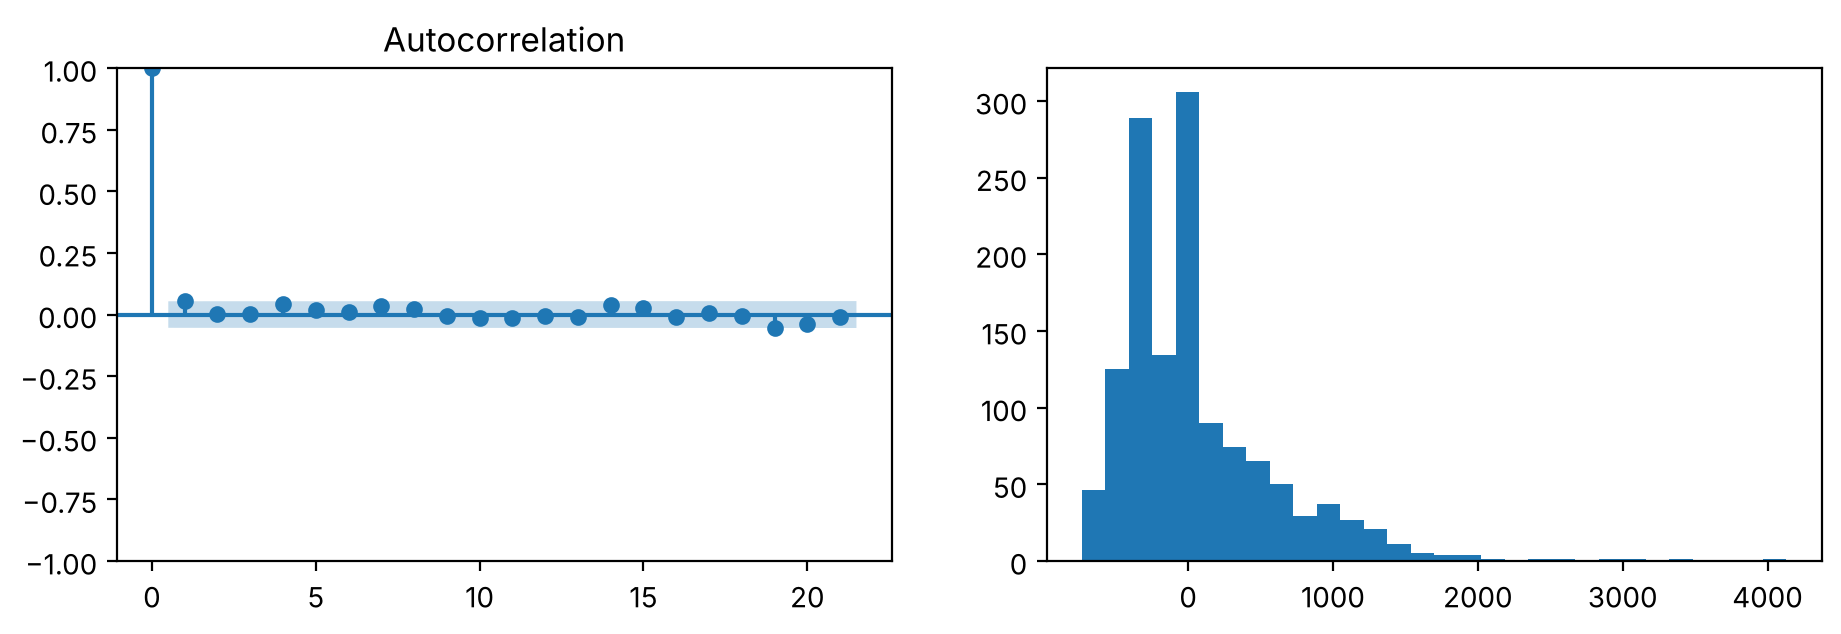

,lb_stat,lb_pvalue
7,8.311127,0.305960
14,12.068055,0.600837


In [6]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
r = fit.resid[14:].dropna()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
plot_acf(r, lags=21, ax=ax[0]); ax[1].hist(r, bins=30); plt.show()
acorr_ljungbox(r, lags=[7, 14], return_df=True)

El MA estacional sale en −0.9997: casi cancela la diferencia estacional. En la práctica el modelo aprendió un promedio estable por día de la semana y nada más, porque la venta de un día casi no dice nada del siguiente (ACF de rezago 1 = 0.08 en E2). Por eso empata con el promedio por día de la semana.

## 4. Pronóstico a 30 días con la versión final (toda la historia)

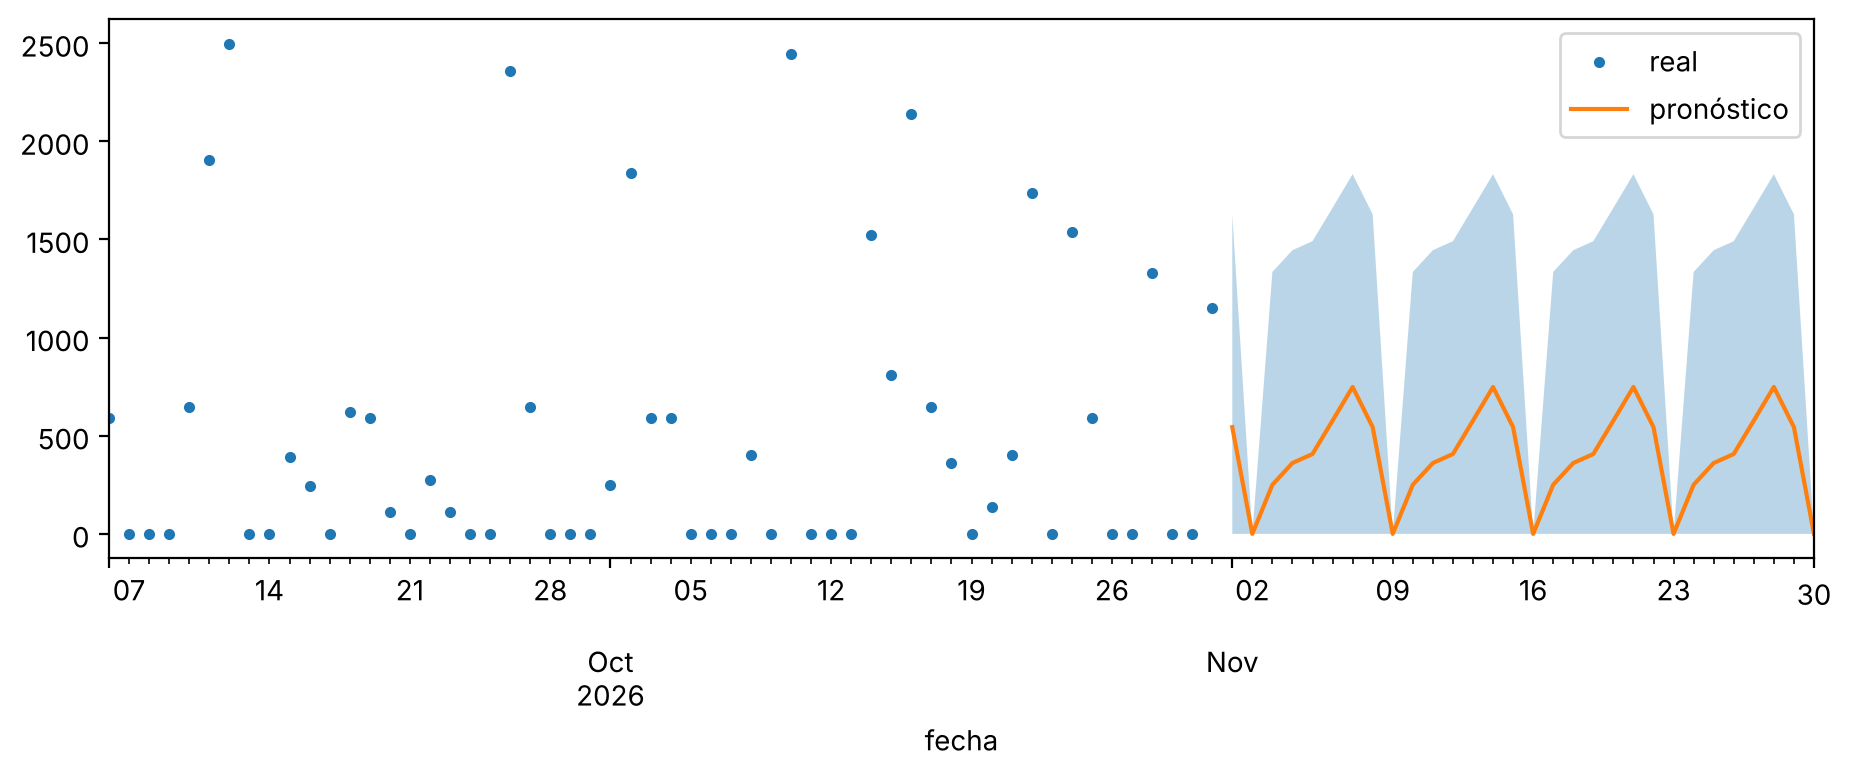

,pronostico,inferior,superior
fecha,,,
2026-11-01,544.0,0.0,1628.0
2026-11-02,0.0,0.0,0.0
2026-11-03,250.0,0.0,1334.0
2026-11-04,361.0,0.0,1445.0
2026-11-05,407.0,0.0,1491.0
2026-11-06,577.0,0.0,1661.0
2026-11-07,748.0,0.0,1832.0
2026-11-08,544.0,0.0,1628.0
2026-11-09,0.0,0.0,0.0


In [7]:
spec = pickle.loads((RAIZ / "models/sarima_venta_v1.pkl").read_bytes())
f = nu.pronostico(nu.aplicar_sarima(spec, y), 30)
ax = y[-56:].plot(style="o", ms=3, figsize=(11, 3.5), label="real")
f.pronostico.plot(ax=ax, label="pronóstico"); ax.fill_between(f.index, f.inferior, f.superior, alpha=.3); ax.legend(); plt.show()
f.head(10).round(0)

## 5. Clasificador: ¿2 o más pasteles enteros?, decidido dos días antes

In [8]:
print(R["clasificador_datos"])
pd.DataFrame(R["clasificador"]).T[["f2_cv", "precision", "recall", "f1", "f2", "auc"]].astype(float).round(3)

{'dias_entrenamiento': 1139, 'dias_prueba': 296, 'tasa_alto_entrenamiento': 0.22388059701492538, 'tasa_alto_prueba': 0.21621621621621623}


,f2_cv,precision,recall,f1,f2,auc
Naive Bayes,0.658,0.610,0.734,0.667,0.706,0.846
SVM (RBF),0.684,0.595,0.781,0.676,0.735,0.849
KNN,0.532,0.702,0.625,0.661,0.639,0.801
Árbol de decisión,0.685,0.625,0.781,0.694,0.744,0.866
Regla simple (apartados y fin de semana),NaN,0.691,0.734,0.712,0.725,NaN


In [9]:
from sklearn.tree import export_text
arbol = pickle.loads((RAIZ / "models/clasificador_dia_fuerte_v1.pkl").read_bytes())
print(export_text(arbol, feature_names=nu.COLUMNAS_X))

|--- apartados_pedidos <= 0.50
|   |--- mar_jue <= 0.50
|   |   |--- class: 0
|   |--- mar_jue >  0.50
|   |   |--- class: 0
|--- apartados_pedidos >  0.50
|   |--- apartados_enteros <= 1.50
|   |   |--- class: 1
|   |--- apartados_enteros >  1.50
|   |   |--- class: 1



In [10]:
json.loads((RAIZ / "models/registro.json").read_text())

{'version': 1,
 'entrenado_en': '2026-11-12T15:41:35+00:00',
 'datos': {'archivo': 'pedidos_salome_clean.csv',
  'renglones': 2614,
  'pedidos': 1963,
  'sha256': '9c190b4aaac6480f',
  'hasta': '2026-10-31'},
 'sarima': {'orden': [0, 0, 0],
  'estacional': [0, 1, 1, 7],
  'metricas_prueba': {'MAE': 498.4324897498289,
   'RMSE': 682.3285103851435,
   'n': 295,
   'aic': 20517.3,
   'bic': 20527.8,
   'parametros': 2,
   'cobertura_95': 0.8817567567567568}},
 'clasificador': {'modelo': 'Árbol de decisión',
  'parametros': {'max_depth': 2, 'min_samples_leaf': 20},
  'umbral_enteros': 2,
  'columnas': ['apartados_enteros',
   'apartados_pedidos',
   'enteros_hace_7',
   'media_enteros_28',
   'fecha_fuerte',
   'vispera',
   'quincena',
   'es_diciembre',
   'es_mayo',
   'vie',
   'sab',
   'dom',
   'mar_jue'],
  'metricas_prueba': {'precision': 0.625,
   'recall': 0.78125,
   'f1': 0.6944444444444444,
   'f2': 0.7440476190476191,
   'auc': 0.8661772629310345},
  'anticipo_dias': 2},
 'a